# Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import kagglehub
import scipy as sp

from sklearn import preprocessing
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score, KFold, GridSearchCV, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import SimpleImputer, IterativeImputer
from sklearn.linear_model import LogisticRegression


from xgboost import XGBClassifier

/home/mawkli/Projects/Youcode/sanity_check/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Download DataSet

In [2]:
# PATH = kagglehub.dataset_download("maqdadali/mental-health-risk-prediction-dataset-students")

In [3]:
# print(PATH)

In [4]:
# !cp ~/.cache/kagglehub/datasets/maqdadali/mental-health-risk-prediction-dataset-students/versions/1/student_mental_health.csv ~/Projects/Youcode/sanity_check

# Load Dataset

In [5]:
df = pd.read_csv("../student_mental_health.csv")

In [6]:
df.head(10)

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium
5,STU0006,20,Female,4,6.8,18.6,NaN,8.5,11.8,High,7.0,3.9,NaN,Yes,Average,No,Medium
6,STU0007,24,Male,2,7.7,15.0,2.77,8.8,10.2,Low,6.1,7.7,100.0,No,Good,No,Low
7,STU0008,23,Non-binary,3,7.9,20.5,2.65,6.1,7.6,Low,NaN,6.5,78.9,No,Average,Yes,Medium
8,STU0009,20,Female,3,6.2,28.6,2.42,3.9,7.2,Moderate,5.3,8.4,72.6,No,Good,No,Low
9,STU0010,22,Male,3,6.6,20.5,2.28,6.9,7.4,Moderate,7.3,5.7,92.7,No,Average,No,Medium


# EDA

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 1953 non-null

In [8]:
df.shape

(2000, 17)

In [9]:
df.describe()

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
count,2000.000000,2000.000000,1938.000000,2000.000000,1962.000000,1942.000000,2000.000000,1909.000000,1946.000000,1953.000000
mean,21.131500,2.630000,6.758875,19.997900,2.562503,6.013955,8.548500,5.956260,6.518345,85.080236
std,2.139275,1.316802,1.127072,5.719274,0.343993,1.153422,1.657571,1.893941,1.844639,7.224118
min,17.000000,1.000000,3.300000,2.400000,1.500000,2.100000,3.300000,1.400000,1.700000,54.400000
25%,20.000000,1.000000,6.000000,16.000000,2.320000,5.225000,7.400000,4.500000,5.100000,80.300000
50%,21.000000,2.000000,6.700000,19.800000,2.560000,6.000000,8.500000,6.100000,6.700000,85.100000
75%,23.000000,4.000000,7.600000,24.000000,2.790000,6.700000,9.700000,7.400000,8.000000,90.000000
max,29.000000,5.000000,10.000000,38.300000,3.660000,10.000000,14.000000,10.000000,9.900000,100.000000


In [10]:
print(f"Nulls:\n{df.isnull().sum()}\n")
print(f"Total nulls:\n {df.isnull().sum().sum()}\n\n")
print(f"Duplicates:\n{df.duplicated().sum()}\n\n")

Nulls:
Student_ID                         0
Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       62
Study_Hours_Per_Week               0
GPA                               38
Social_Media_Hours                58
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  91
Family_Support                    54
Attendance_Rate                   47
Part_Time_Job                      0
Diet_Quality                      69
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64

Total nulls:
 419


Duplicates:
0




In [11]:
print(f"{df[['Gender', 'Age']].groupby('Gender').mean()}\n")
print(f"{df[['Gender', 'GPA']].groupby('Gender').mean()}\n")
print(f"{df[['Gender', 'Social_Media_Hours']].groupby('Gender').mean()}\n")
for gender in df["Gender"].unique():
    print(f"*************{gender}*************\n")
    temp = df.loc[df["Gender"] == gender, "Mental_Health_Risk"]
    for risk in temp.unique():
        print(f"Total {risk} from the {gender} gender: {temp.loc[temp == risk].count()}\n")
    print("\n\n\n")

                  Age
Gender               
Female      21.262616
Male        20.991416
Non-binary  21.164948

                 GPA
Gender              
Female      2.570116
Male        2.555546
Non-binary  2.553368

            Social_Media_Hours
Gender                        
Female                5.993862
Male                  6.045011
Non-binary            5.918947

*************Male*************

Total High from the Male gender: 311

Total Medium from the Male gender: 325

Total Low from the Male gender: 296





*************Female*************

Total Medium from the Female gender: 310

Total Low from the Female gender: 325

Total High from the Female gender: 336





*************Non-binary*************

Total Medium from the Non-binary gender: 25

Total High from the Non-binary gender: 33

Total Low from the Non-binary gender: 39







In [12]:
print(f"Inconsistante data:\n")
print(f"{df[df['Social_Media_Hours'] > df['Screen_Time_Hours']].shape[0]}\n")
temp = df['Age']-df['Year_of_Study']
print(f"{np.sort(temp.unique())}\n")
print(f"{np.sort(df[df['Age']-df['Year_of_Study'] <=16]['GPA'].dropna().unique())}\n")

Inconsistante data:

37

[12 13 14 15 16 17 18 19 20 21 22 23 24 25 26]

[1.76 1.79 1.8  1.81 1.82 1.85 1.88 1.91 1.98 1.99 2.   2.01 2.02 2.05
 2.07 2.09 2.1  2.11 2.12 2.13 2.14 2.15 2.17 2.18 2.19 2.2  2.21 2.22
 2.23 2.24 2.25 2.26 2.27 2.28 2.29 2.3  2.31 2.32 2.33 2.34 2.35 2.36
 2.37 2.38 2.39 2.4  2.41 2.42 2.43 2.44 2.45 2.46 2.47 2.48 2.49 2.5
 2.51 2.52 2.53 2.54 2.55 2.56 2.57 2.58 2.59 2.6  2.61 2.62 2.63 2.64
 2.65 2.66 2.67 2.68 2.69 2.7  2.71 2.72 2.73 2.75 2.76 2.77 2.78 2.79
 2.8  2.81 2.82 2.83 2.84 2.85 2.86 2.87 2.88 2.89 2.9  2.91 2.92 2.93
 2.94 2.95 2.96 2.97 2.98 2.99 3.   3.01 3.02 3.03 3.04 3.05 3.07 3.08
 3.09 3.1  3.11 3.12 3.13 3.15 3.16 3.17 3.18 3.19 3.21 3.22 3.23 3.24
 3.25 3.26 3.27 3.28 3.3  3.32 3.33 3.34 3.36 3.37 3.38 3.39 3.4  3.47
 3.66]



add Year where he started uni

## Graphs

In [13]:
quantitative = {
    "continuous":["Sleep_Hours", "Study_Hours_Per_Week", "GPA", "Social_Media_Hours", "Screen_Time_Hours", "Financial_Stress", "Family_Support", "Attendance_Rate"],
    "discrete":["Age", "Year_of_Study", ],
}
qualitative = {
    "nominal":["Gender", "Part_Time_Job", "Previous_Mental_Health_History"],
    "ordinal":["Physical_Activity", "Diet_Quality", "Mental_Health_Risk"],
    "ordinal_order":{
        "Physical_Activity":["Low", "Moderate", "High"],
        "Diet_Quality":["Poor", "Average", "Good"],
        "Mental_Health_Risk":["Low", "Medium", "High"],
    }
}

In [14]:

for col in qualitative["ordinal"]:
    print(col)
    print(df[col].unique())

Physical_Activity
<ArrowStringArray>
['Moderate', 'Low', 'High']
Length: 3, dtype: str
Diet_Quality
<ArrowStringArray>
['Poor', 'Average', nan, 'Good']
Length: 4, dtype: str
Mental_Health_Risk
<ArrowStringArray>
['High', 'Medium', 'Low']
Length: 3, dtype: str


### Single variable

#### Quantitative

In [15]:
def draw_quant(df):
    fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(15, 4))
    row = 0
    col = 0
    for column in df[quantitative["continuous"]].columns:
        sns.histplot(data=df[column], ax=axes[row, col])
        axes[row, col].set_title(column)
        if col == 4:
            row = 1
            col = 0
        else:
            col += 1
    for column in df[quantitative["discrete"]].columns:
        sns.histplot(data=df[column], ax=axes[1,col], discrete=True)
        axes[1,col].set_title(column)
        col += 1
    plt.tight_layout()
    plt.show()

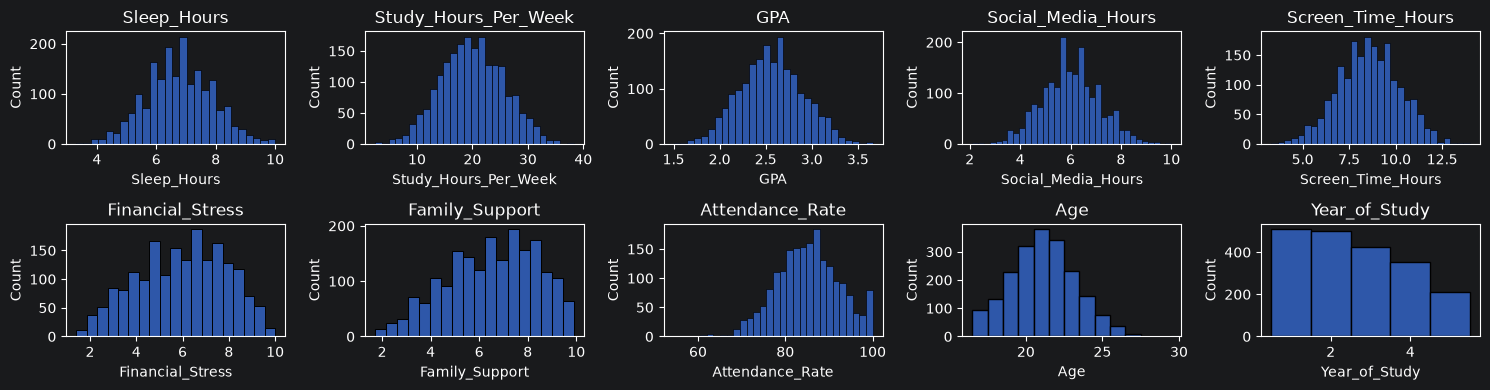

In [16]:
draw_quant(df)

In [17]:
def draw_quant_box(df):
    fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(8, 15))
    row = 0
    col = 0
    for column in df[quantitative["continuous"]].columns:
        sns.boxplot(data=df[column], ax=axes[row, col])
        axes[row, col].set_title(column)
        if col == 4:
            row = 1
            col = 0
        else:
            col += 1
    for column in df[quantitative["discrete"]].columns:
        sns.boxplot(data=df[column], ax=axes[1,col])
        axes[1,col].set_title(column)
        col += 1
    plt.tight_layout()
    plt.show()

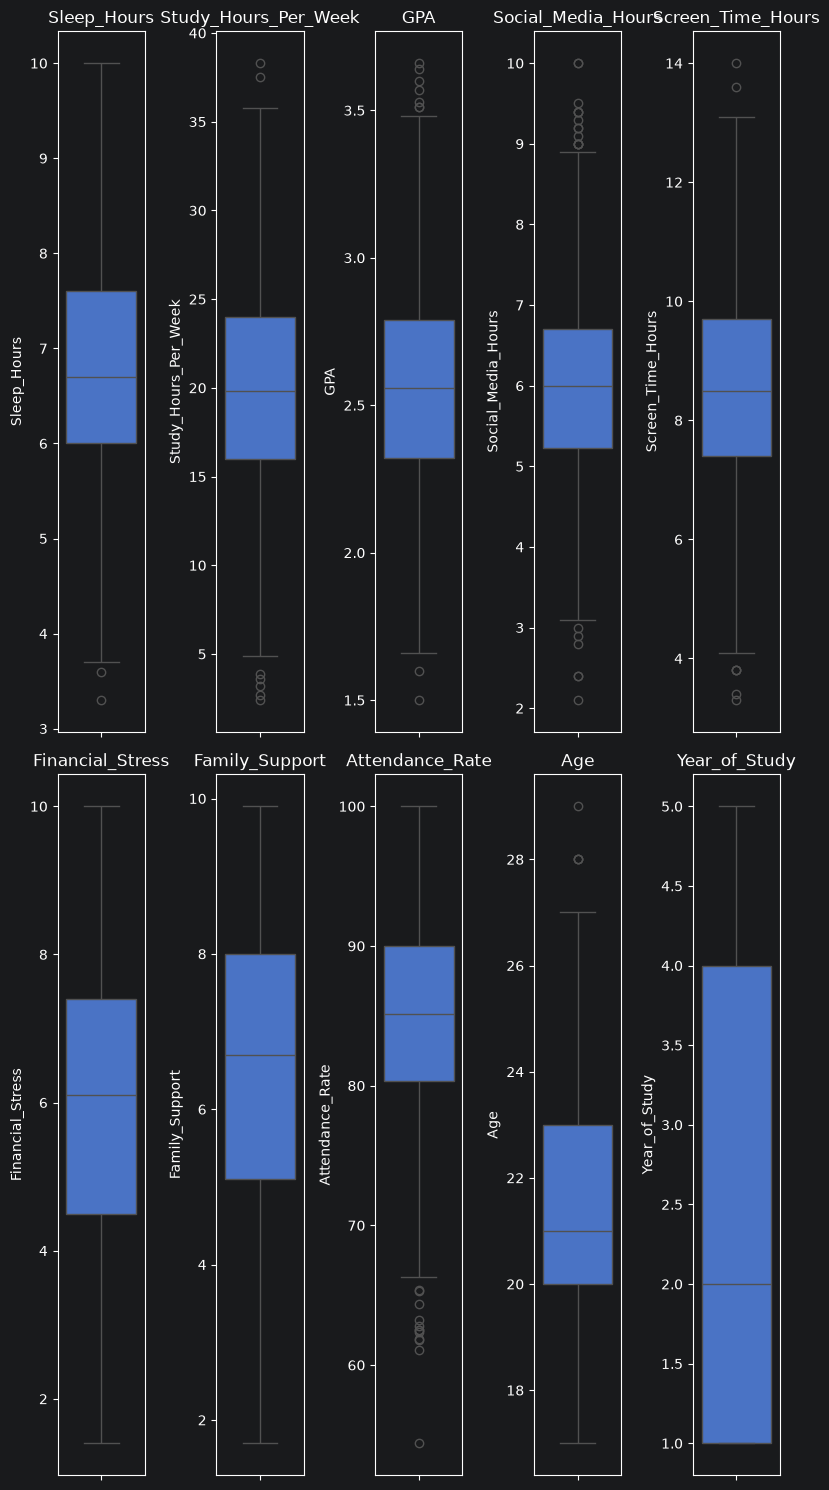

In [18]:
draw_quant_box(df)

#### Qualitative

In [19]:
def draw_qual(df):
    fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 4))
    row = 0
    col = 0
    for column in df[qualitative["nominal"]].columns:
        sns.countplot(data=df[column], ax=axes[row,col])
        axes[row,col].set_title(column)
        if col == 2:
            row = 1
            col = 0
        else:
            col += 1

    for column in df[qualitative["ordinal"]].columns:
        sns.countplot(data=df[column], ax=axes[row,col], order=qualitative["ordinal_order"][column])
        axes[row,col].set_title(column)
        col += 1

    plt.tight_layout()
    plt.show()

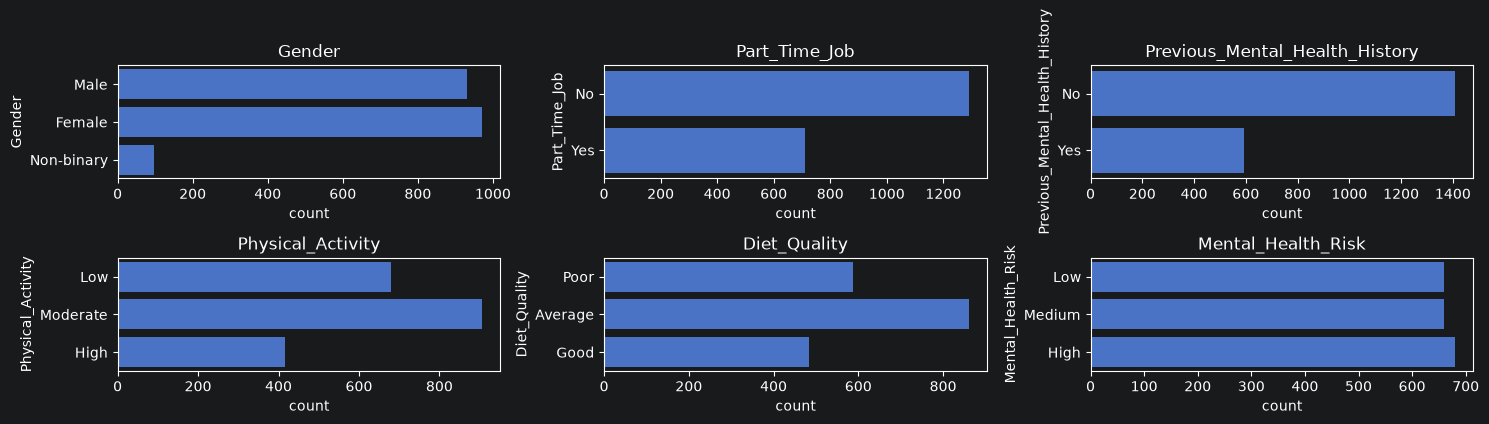

In [20]:
draw_qual(df)

### MultiVariable

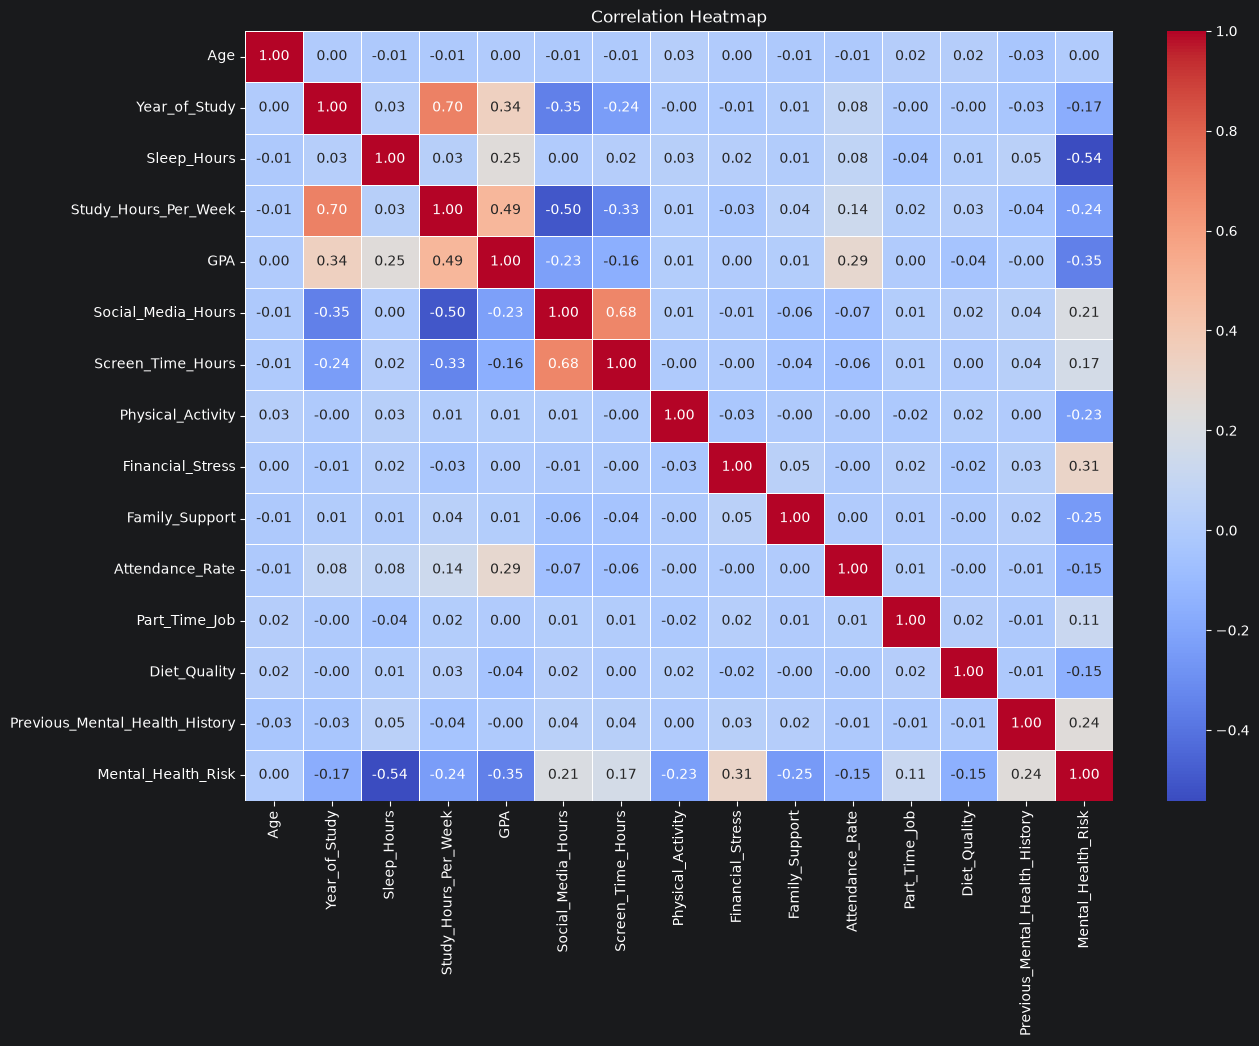

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,22,3,6.6,17.6,2.91,6.9,7.5,1,8.5,4.0,78.0,0,0.0,0,2
1,21,4,5.6,22.4,2.92,7.6,11.5,0,4.5,5.3,85.4,1,1.0,0,1
2,22,5,7.1,28.1,2.68,6.5,8.9,0,4.8,6.1,79.5,0,1.0,0,1
3,24,1,4.5,14.8,2.23,5.5,7.6,2,3.7,8.0,73.9,0,1.0,1,2
4,20,1,6.7,17.2,2.69,4.3,7.0,1,8.0,7.4,99.8,1,NaN,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,23,2,7.5,20.3,1.89,7.3,10.7,2,8.2,6.3,80.9,0,1.0,0,1
1996,21,2,6.4,16.8,2.14,4.6,5.8,1,4.6,3.5,76.9,1,0.0,0,2
1997,19,1,4.5,13.1,2.54,7.5,10.0,0,6.7,8.1,87.9,1,NaN,0,2
1998,21,3,8.1,22.3,2.62,4.5,6.6,1,6.5,8.4,100.0,0,2.0,0,0


In [21]:
temp_df = df.copy()
temp_df = temp_df.drop(columns=["Gender", "Student_ID"])
temp_df["Mental_Health_Risk"] = temp_df["Mental_Health_Risk"].map({"Low":0, "Medium":1, "High":2})
temp_df["Diet_Quality"] = temp_df["Diet_Quality"].map({"Poor":0, "Average":1, "Good":2})
temp_df["Physical_Activity"] = temp_df["Physical_Activity"].map({"Low":0, "Moderate":1, "High":2})

temp_df["Previous_Mental_Health_History"] = temp_df["Previous_Mental_Health_History"].map({"Yes":1, "No":0})
temp_df["Part_Time_Job"] = temp_df["Part_Time_Job"].map({"Yes":1, "No":0})

matrix = temp_df.corr()
plt.figure(figsize=(14,10))
sns.heatmap(matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()
temp_df

In [22]:
def box_for_two(quant, qual):
    fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20, 10))
    row = 0
    col = 0

    for column in quant.columns:
        sns.boxplot(y=quant[column], x=df["Mental_Health_Risk"], ax=axes[row, col])
        axes[row, col].set_title(f"{column} vs MentalHealth Risk")
        if col == 3:
            row = 1
            col = 0
        else:
            col += 1

    for column in qual.columns:
        sns.countplot(x=qual[column], hue=df["Mental_Health_Risk"], ax=axes[row, col])
        axes[row, col].set_title(f"{column} vs MentalHealth Risk")
        col += 1
    plt.show()

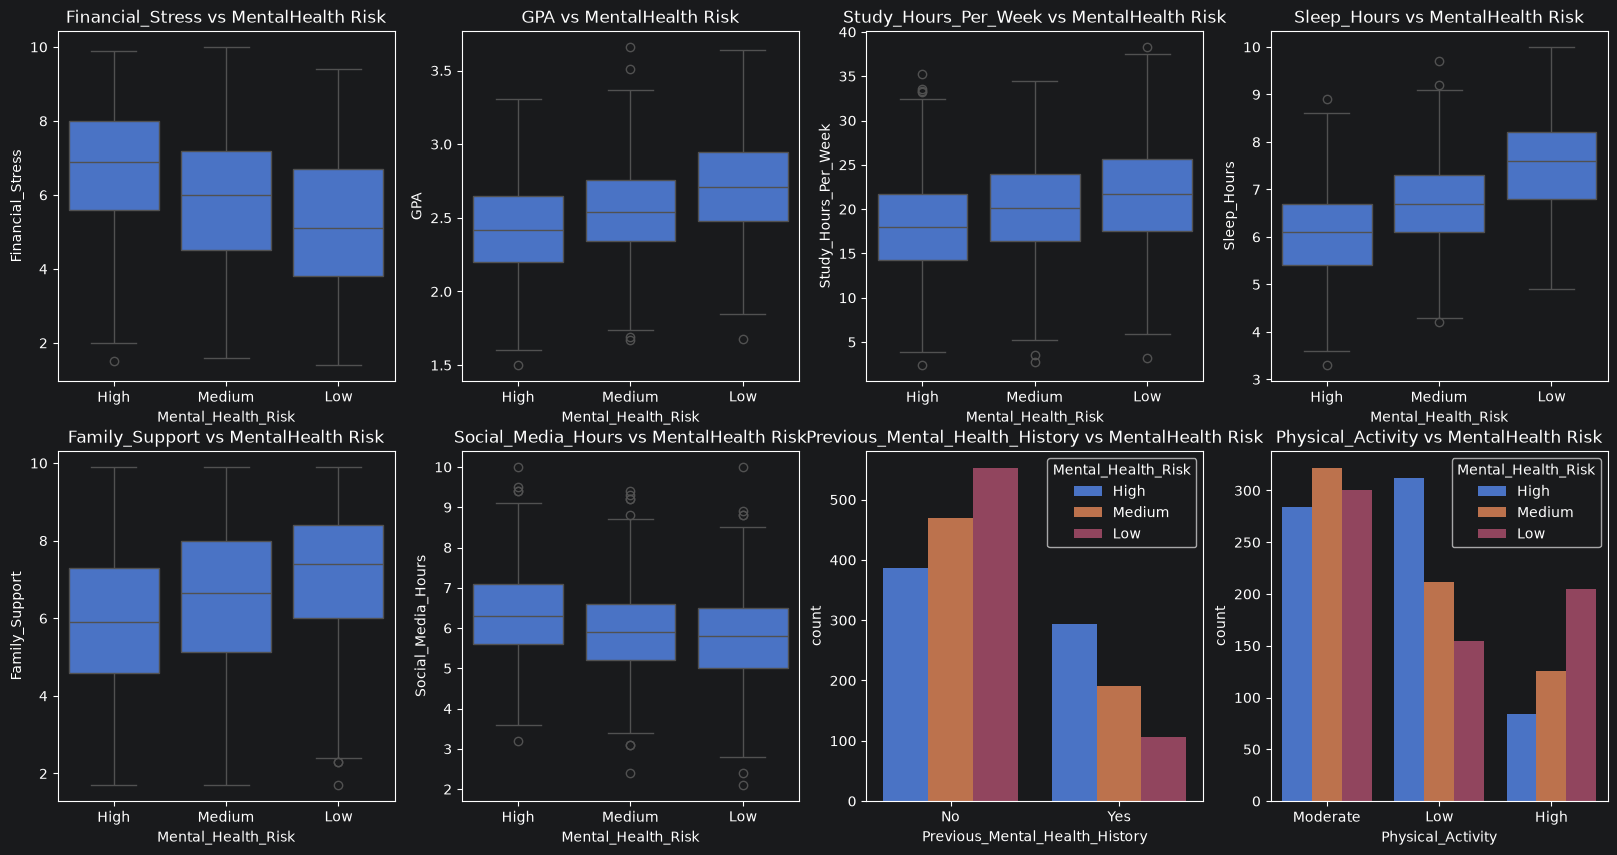

In [23]:
temp_quant = df[["Financial_Stress", "GPA", "Study_Hours_Per_Week", "Sleep_Hours", "Family_Support", "Social_Media_Hours"]]
temp_qual = df[["Previous_Mental_Health_History", "Physical_Activity"]]
box_for_two(temp_quant, temp_qual)

# Preprocessing

In [24]:
def clean_null_duplicates(dataF):
    dataF = dataF.drop(columns="Student_ID")
    # dataF = dataF.dropna(subset=list(qualitative["nominal"]) + list(qualitative["ordinal"]))
    dataF = dataF.drop_duplicates()
    return dataF


In [25]:
df= clean_null_duplicates(df)

In [26]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Age                             2000 non-null   int64  
 1   Gender                          2000 non-null   str    
 2   Year_of_Study                   2000 non-null   int64  
 3   Sleep_Hours                     1938 non-null   float64
 4   Study_Hours_Per_Week            2000 non-null   float64
 5   GPA                             1962 non-null   float64
 6   Social_Media_Hours              1942 non-null   float64
 7   Screen_Time_Hours               2000 non-null   float64
 8   Physical_Activity               2000 non-null   str    
 9   Financial_Stress                1909 non-null   float64
 10  Family_Support                  1946 non-null   float64
 11  Attendance_Rate                 1953 non-null   float64
 12  Part_Time_Job                   2000 non-null

In [27]:
X = df.drop(columns="Mental_Health_Risk")
Y = df["Mental_Health_Risk"]
Y = Y.map({"Low":0, "Medium":1, "High":2})


In [28]:
def gotta_catch_them_all(data):
    data = data.copy()
    for col in data.columns:
        z = sp.stats.zscore(data[col], nan_policy="omit")
        inliers = data.loc[np.abs(z) < 3, col]
        data[col] = data[col].clip(inliers.min(), inliers.max())
    return data

In [29]:
X[quantitative["continuous"] + quantitative["discrete"]] = gotta_catch_them_all(X[quantitative["continuous"] + quantitative["discrete"]])

## Train test split

In [30]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42, stratify=Y
)

## Pipeline

In [31]:
def ginki_dama(data):
    data = data.copy()
    data["Start_Age"] = data["Age"] - data["Year_of_Study"].round()
    data["Social_Media_Hours"] = data["Social_Media_Hours"].clip(upper=data["Screen_Time_Hours"])
    # mask = data["Social_Media_Hours"] > data["Screen_Time_Hours"]
    #
    # data.loc[mask, ["Social_Media_Hours", "Screen_Time_Hours"]] = (
    #     data.loc[mask, ["Screen_Time_Hours", "Social_Media_Hours"]].values
    # )
    return data

def ginki_names(transformer, input_features):
    return list(input_features) + ["Start_Age"]

In [32]:
imputable_cols = ["Study_Hours_Per_Week", "Year_of_Study", "GPA", "Sleep_Hours", "Social_Media_Hours", "Screen_Time_Hours", "Attendance_Rate"]
other_quant = [c for c in quantitative["continuous"] + quantitative["discrete"]
               if c not in imputable_cols]

quant_pipe = ColumnTransformer(
    transformers=[
        ("stage_1", IterativeImputer(max_iter=10, random_state=42), imputable_cols),
        ("stage_2", SimpleImputer(strategy="median"), other_quant),
        # ("stage_3", SimpleImputer(strategy="median"), quantitative["continuous"] + quantitative["discrete"]),
    ],
    verbose_feature_names_out=False,
).set_output(transform="pandas")

great_quant_pipe = Pipeline(steps=[
    ("imputation", quant_pipe),
    # ("stage_2", SimpleImputer(strategy="median")),
    ("ginki_dama", FunctionTransformer(ginki_dama, feature_names_out=ginki_names)),
    ("scaler", StandardScaler()),
])

nominal_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])
ordinal_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
])

In [33]:

preprocessing = ColumnTransformer(
    transformers=[
        ("quant", great_quant_pipe, quantitative["continuous"] + quantitative["discrete"]),
        ("nominal", nominal_pipe, qualitative["nominal"]),
        ("ordinal", ordinal_pipe, ["Physical_Activity", "Diet_Quality"]),

    ],
    remainder="drop",
)

# Modelisation

### RanfomForestClassifier

In [34]:
RFC = Pipeline([
    ("preprocessor", preprocessing),
    ("classifier", RandomForestClassifier(n_estimators=100, random_state=42, max_depth=3)),
])

In [35]:
RFC.fit(X_train, Y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['Age','Gender','Year_of_Study',...,'Part_Time_Job','Diet_Quality', 'Previous_Mental_Health_History']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('quant', ...), ('nominal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``)

### XGBoost

In [36]:
params = {
    "objective": "multi: softmax",
    "max_depth": 3,
    "learning_rate": 0.01,
    "n_estimators": 100,
    "alpha":10
}


XGB = Pipeline([
    ("preprocessor", preprocessing),
    ("classifier", XGBClassifier(**params))
])

In [37]:
XGB.fit(X_train, Y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['Age','Gender','Year_of_Study',...,'Part_Time_Job','Diet_Quality', 'Previous_Mental_Health_History']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('quant', ...), ('nominal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``)

### KNN

In [38]:
KNN = Pipeline([
    ("preprocessor", preprocessing),
    ("classifier", KNeighborsClassifier(n_neighbors=4)),
])

In [39]:
KNN.fit(X_train, Y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['Age','Gender','Year_of_Study',...,'Part_Time_Job','Diet_Quality', 'Previous_Mental_Health_History']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('quant', ...), ('nominal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``)

### Logistic Regression

In [40]:
LRP = Pipeline([
    ("preprocessor", preprocessing),
    ("classifier", LogisticRegression(random_state=42)),
])

In [41]:
LRP.fit(X_train, Y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['Age','Gender','Year_of_Study',...,'Part_Time_Job','Diet_Quality', 'Previous_Mental_Health_History']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('quant', ...), ('nominal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``)

# Scoring

In [42]:
models = {"RandomForestClassifier": RFC, "XGBoost": XGB, "KNeighborsClassifier": KNN, "LogisticRegression": LRP}

In [43]:
def compare_models(models):
    scores={}
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    scoring = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]
    for model_name, model in models.items():
        results = cross_validate(model, X_train, Y_train, cv=skf, scoring=scoring)
        print(f"------{model_name}------")
        for metric in scoring:
            scores = results[f"test_{metric}"]
            print(f"{metric}: {scores.mean():.3f}, std: {scores.std():.3f}  (per fold: {scores.round(3)})")
        model.fit(X_train, Y_train)
        prediction = model.predict(X_test)

        Y_test_mapped = Y_test.map({0:"Low", 1:"Medium", 2:"High"}).reset_index(drop=True)
        prediction_mapped = pd.Series(prediction).map({0: "Low", 1: "Medium", 2: "High"})

        ConfusionMatrixDisplay.from_predictions(Y_test_mapped, prediction_mapped, cmap="Blues")
        plt.show()


        comp = pd.DataFrame({
            "Predicted": prediction_mapped,
            "Actual": Y_test_mapped,
        }, index=range(len(Y_test_mapped)), columns=["Predicted", "Actual"])
        print(comp)
        print("\n\n\n")
        print(classification_report(
            Y_test,
            prediction,
            target_names=["Low", "Medium", "High"]
))


In [44]:
# score = cross_val_score(cv=5, estimator=RFC, X=X_train, y=Y_train, scoring="accuracy")

In [45]:
# pred = RFC.predict(X_test)
# print(len(pred))
# print(len(Y_test))

------RandomForestClassifier------
accuracy: 0.641, std: 0.028  (per fold: [0.659 0.591 0.631 0.656 0.666])
precision_macro: 0.622, std: 0.035  (per fold: [0.646 0.559 0.607 0.644 0.652])
recall_macro: 0.639, std: 0.027  (per fold: [0.659 0.589 0.63  0.653 0.663])
f1_macro: 0.609, std: 0.032  (per fold: [0.631 0.551 0.598 0.625 0.638])


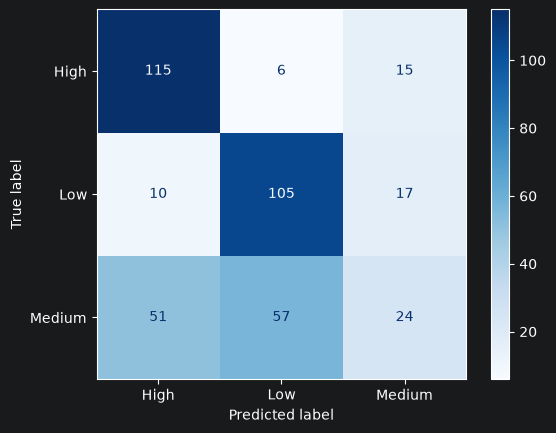

    Predicted  Actual
0         Low  Medium
1         Low     Low
2         Low     Low
3        High    High
4         Low  Medium
..        ...     ...
395      High    High
396       Low     Low
397       Low     Low
398      High    High
399       Low  Medium

[400 rows x 2 columns]




              precision    recall  f1-score   support

         Low       0.62      0.80      0.70       132
      Medium       0.43      0.18      0.26       132
        High       0.65      0.85      0.74       136

    accuracy                           0.61       400
   macro avg       0.57      0.61      0.56       400
weighted avg       0.57      0.61      0.57       400

------XGBoost------
accuracy: 0.622, std: 0.027  (per fold: [0.653 0.603 0.603 0.594 0.656])
precision_macro: 0.612, std: 0.030  (per fold: [0.645 0.589 0.591 0.584 0.653])
recall_macro: 0.621, std: 0.027  (per fold: [0.652 0.603 0.602 0.592 0.654])
f1_macro: 0.612, std: 0.029  (per fold: [0.643 0.588 0.591 0.584 0.651])


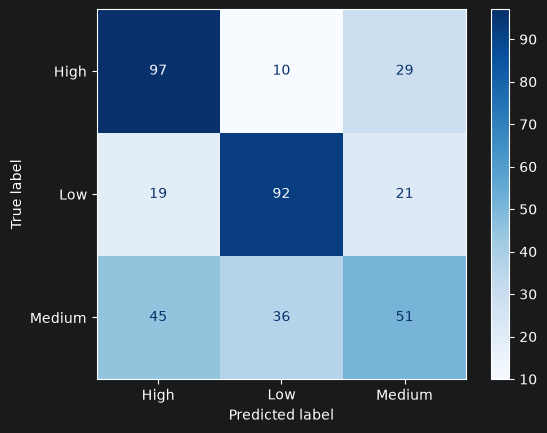

    Predicted  Actual
0         Low  Medium
1         Low     Low
2        High     Low
3        High    High
4      Medium  Medium
..        ...     ...
395      High    High
396       Low     Low
397       Low     Low
398    Medium    High
399    Medium  Medium

[400 rows x 2 columns]




              precision    recall  f1-score   support

         Low       0.67      0.70      0.68       132
      Medium       0.50      0.39      0.44       132
        High       0.60      0.71      0.65       136

    accuracy                           0.60       400
   macro avg       0.59      0.60      0.59       400
weighted avg       0.59      0.60      0.59       400

------KNeighborsClassifier------
accuracy: 0.561, std: 0.028  (per fold: [0.578 0.591 0.578 0.544 0.516])
precision_macro: 0.571, std: 0.035  (per fold: [0.591 0.614 0.588 0.55  0.514])
recall_macro: 0.562, std: 0.028  (per fold: [0.58  0.592 0.578 0.544 0.516])
f1_macro: 0.559, std: 0.030  (per fold: [0.574 0.593 0.579 0.541

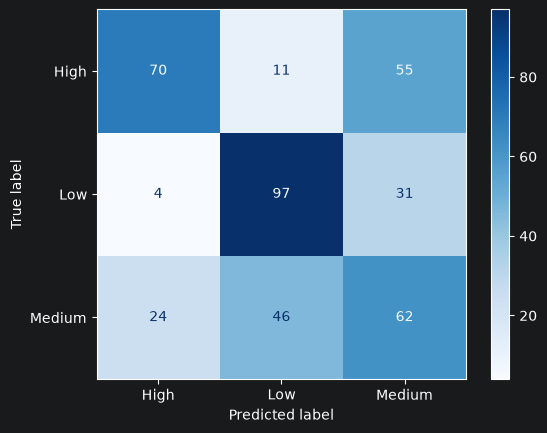

    Predicted  Actual
0        High  Medium
1         Low     Low
2         Low     Low
3        High    High
4         Low  Medium
..        ...     ...
395      High    High
396       Low     Low
397       Low     Low
398      High    High
399    Medium  Medium

[400 rows x 2 columns]




              precision    recall  f1-score   support

         Low       0.63      0.73      0.68       132
      Medium       0.42      0.47      0.44       132
        High       0.71      0.51      0.60       136

    accuracy                           0.57       400
   macro avg       0.59      0.57      0.57       400
weighted avg       0.59      0.57      0.57       400

------LogisticRegression------
accuracy: 0.700, std: 0.012  (per fold: [0.716 0.691 0.681 0.706 0.706])
precision_macro: 0.699, std: 0.013  (per fold: [0.714 0.695 0.677 0.709 0.7  ])
recall_macro: 0.699, std: 0.012  (per fold: [0.716 0.69  0.681 0.705 0.705])
f1_macro: 0.698, std: 0.012  (per fold: [0.713 0.693 0.678 0.707 0

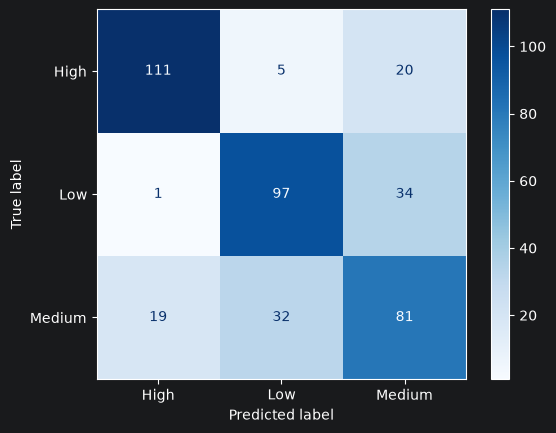

    Predicted  Actual
0      Medium  Medium
1         Low     Low
2         Low     Low
3        High    High
4      Medium  Medium
..        ...     ...
395      High    High
396       Low     Low
397       Low     Low
398      High    High
399    Medium  Medium

[400 rows x 2 columns]




              precision    recall  f1-score   support

         Low       0.72      0.73      0.73       132
      Medium       0.60      0.61      0.61       132
        High       0.85      0.82      0.83       136

    accuracy                           0.72       400
   macro avg       0.72      0.72      0.72       400
weighted avg       0.72      0.72      0.72       400



In [46]:
compare_models(models)

## Optimization

In [47]:
params_grids = {
    "RandomForestClassifier": {
        "classifier__n_estimators": [25, 50, 75, 100],
        'classifier__max_depth': [5, 10, None],
        "classifier__min_samples_split": [2, 5, 10],
        'classifier__random_state': [22, 42, 62]
        },
    "XGBoost": {
        "classifier__objective": ["multi:softmax"],
        "classifier__max_depth": [2,3,5,7],
        "classifier__learning_rate": [0.01, 0.03,0.05, 0.08],
        "classifier__n_estimators": [50, 100, 200, 300],
        "classifier__alpha": [2,5,10,15]
    },
    "KNeighborsClassifier": {
        "classifier__leaf_size":[10,20,30,40],
        "classifier__n_neighbors":[4,6,8,10],
    },
    "LogisticRegression": {
        "classifier__l1_ratio": [0, 1, 0.5],
        "classifier__solver": ["saga"],
        "classifier__random_state": [0,42,100],
        "classifier__max_iter": [200,300,500]
    },
    "LogisticRegression_2": {
        "classifier__l1_ratio": [0],
        "classifier__solver": ["lbfgs", "sag"],
        "classifier__random_state": [0,42,100],
        "classifier__max_iter": [200,300,500]
    }
}


### GridSearch

In [48]:
new_models = {}

def grade(model_name, params):
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    grid = GridSearchCV(
        estimator=models[model_name],
        param_grid=params,
        scoring="accuracy",
        cv=skf,
        n_jobs=-1,
    )
    grid.fit(X_train, Y_train)
    best_params = grid.best_params_
    new_models[model_name] = grid.best_estimator_

    print(f"------{model_name}------")
    print(f"Best score: {grid.best_score_}")
    print(f"Best params: {best_params}")

In [49]:
grade("RandomForestClassifier", params_grids["RandomForestClassifier"])

------RandomForestClassifier------
Best score: 0.6824999999999999
Best params: {'classifier__max_depth': None, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 75, 'classifier__random_state': 42}


In [50]:
# grade("XGBoost", params_grids["XGBoost"])

In [51]:
# grade("KNeighborsClassifier", params_grids["KNeighborsClassifier"])

In [52]:
# grade("LogisticRegression", params_grids["LogisticRegression"])

In [53]:
grade("LogisticRegression", params_grids["LogisticRegression_2"])

------LogisticRegression------
Best score: 0.7
Best params: {'classifier__l1_ratio': 0, 'classifier__max_iter': 200, 'classifier__random_state': 0, 'classifier__solver': 'lbfgs'}


In [54]:
# compare_models(new_models)

In [57]:
print(new_models.keys())

dict_keys(['RandomForestClassifier', 'LogisticRegression'])


In [59]:
joblib.dump(new_models["LogisticRegression"], "LRP.joblib")

['LRP.joblib']